In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))
print("Libraries Imported Successfully!")

I0000 00:00:1793781578.460795      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793781596.112515      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.21.0
GPU Available: []
Libraries Imported Successfully!


E0000 00:00:1793781600.199291      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
# Load MNIST Dataset

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dataset Loaded Successfully!")

print("Training Data Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Testing Data Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)

print("Number of Classes:", len(np.unique(y_train)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset Loaded Successfully!
Training Data Shape: (60000, 28, 28)
Training Labels Shape: (60000,)
Testing Data Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)
Number of Classes: 10


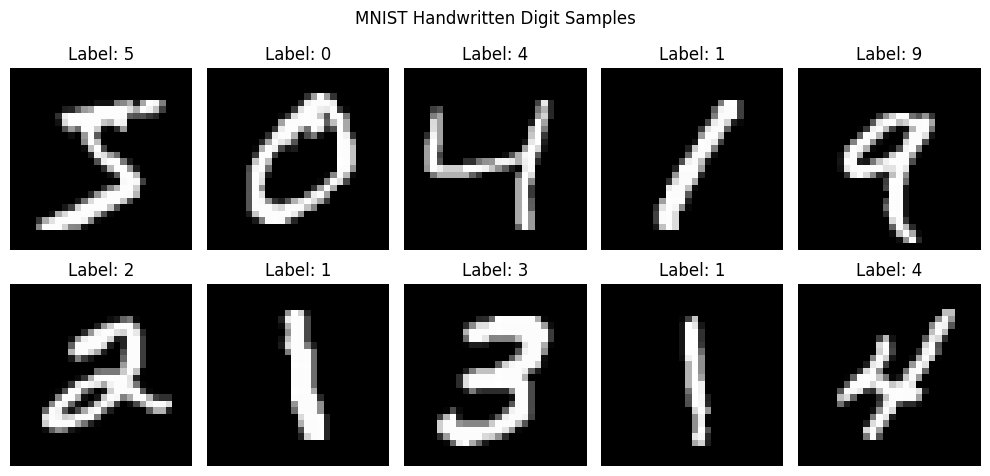

In [3]:
# Display Sample Images

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("MNIST Handwritten Digit Samples")
plt.tight_layout()
plt.show()

In [4]:
# Data Preprocessing

# Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Data Preprocessing Completed!")

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Data Preprocessing Completed!
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [5]:
# Build Deep Learning Neural Network Model

model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dropout(0.2),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display Model Architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train Deep Learning Model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

print("Model Training Completed!")

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8762 - loss: 0.4264 - val_accuracy: 0.9477 - val_loss: 0.1815
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9448 - loss: 0.1871 - val_accuracy: 0.9605 - val_loss: 0.1331
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9585 - loss: 0.1370 - val_accuracy: 0.9677 - val_loss: 0.1144
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9666 - loss: 0.1102 - val_accuracy: 0.9717 - val_loss: 0.0987
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9710 - loss: 0.0939 - val_accuracy: 0.9718 - val_loss: 0.0961
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9746 - loss: 0.0800 - val_accuracy: 0.9732 - val_loss: 0.0908
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9780 - loss: 0.0690 - val_accuracy: 0.9747 - val_loss: 0.0862
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9795 - loss: 0.0632 - val_accuracy: 0.

In [7]:
# Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict test data
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("MODEL EVALUATION RESULTS")
print("-------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
MODEL EVALUATION RESULTS
-------------------------
Accuracy: 0.9787
Precision: 0.9787596403322639
Recall: 0.9787
F1 Score: 0.9786935039598306

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.97      0.98      0.97      1010
           4       0.97      0.98      0.98       982
           5       0.99      0.96      0.98       892
           6       0.98      0.98      0.98       958
           7       0.97      0.98      0.97      1028
           8       0.98      0.97      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



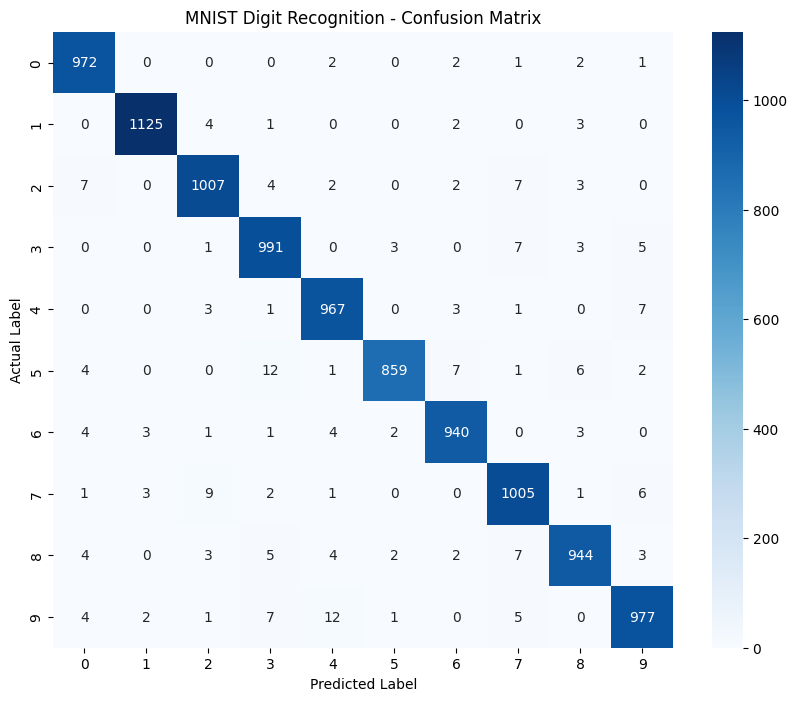

In [8]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("MNIST Digit Recognition - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

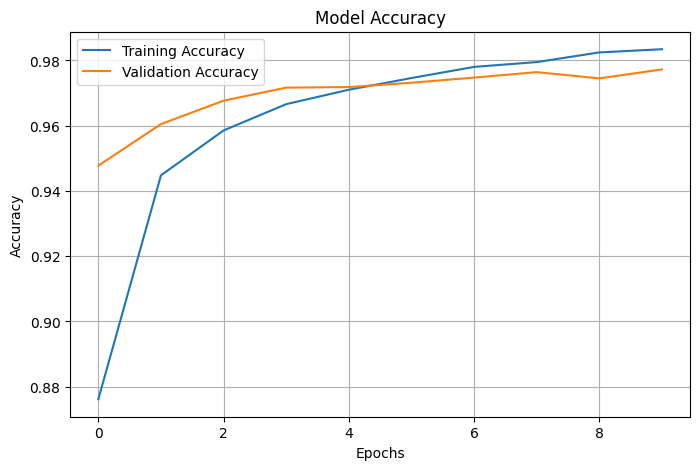

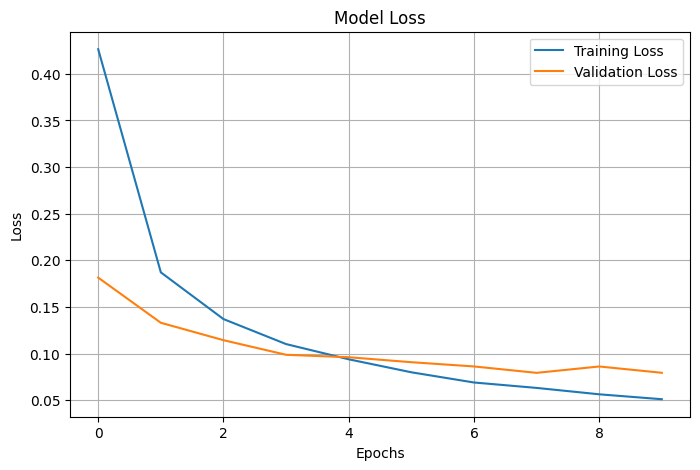

In [9]:
# Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

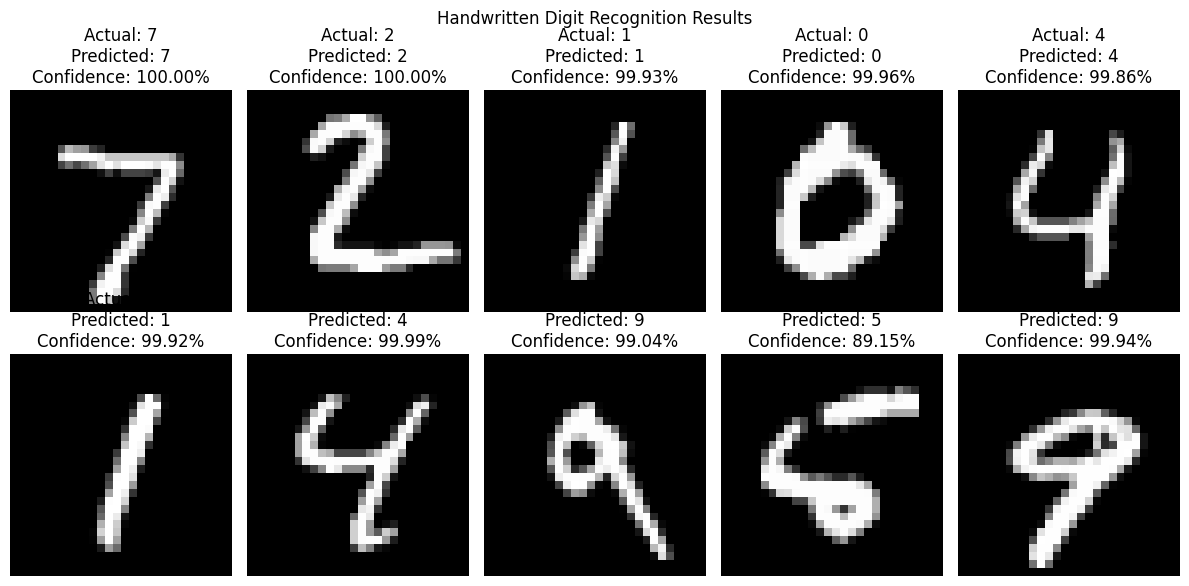

In [10]:
# Handwritten Digit Prediction

plt.figure(figsize=(12, 6))

for i in range(10):
    prediction = model.predict(
        X_test[i:i+1],
        verbose=0
    )

    predicted_digit = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Predicted: {predicted_digit}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis('off')

plt.suptitle("Handwritten Digit Recognition Results")
plt.tight_layout()
plt.show()

In [11]:
# Save the trained model

model.save("mnist_digit_recognition.keras")

print("Model Saved Successfully!")

Model Saved Successfully!
